In [1]:
import pandas as pd

url = r"C:\IT_vedant\Data Manuplation and Staticstics\Netflix (1).csv"
df = pd.read_csv(url)

# 1. Column names -> dtypes
col_dtypes = {col: str(df[col].dtype) for col in df.columns}
print(col_dtypes)

# 2. Duplicates
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)

# 3. Unique release date per title (keep oldest)
df["Release Date"] = pd.to_datetime(df["Release Date"], format="%d-%b-%y", errors="coerce")
df.loc[df["Release Date"] > pd.Timestamp("2021-12-31"), "Release Date"] -= pd.DateOffset(years=100)

n_dates = df.groupby("Title")["Release Date"].nunique()
print("All titles have unique release date?", (n_dates <= 1).all())
print("Titles with multiple dates:", (n_dates > 1).sum())

oldest = df.groupby("Title")["Release Date"].min()
df["Release Date"] = df["Title"].map(oldest)

# 4. Missing value percentage
print((df.isnull().mean() * 100).round(2).sort_values(ascending=False))

{'Title': 'str', 'Genre': 'str', 'Languages': 'str', 'Series or Movie': 'str', 'Hidden Gem Score': 'float64', 'Country Availability': 'str', 'Runtime': 'str', 'Director': 'str', 'Writer': 'str', 'Actors': 'str', 'View Rating': 'str', 'IMDb Score': 'float64', 'Rotten Tomatoes Score': 'float64', 'Metacritic Score': 'float64', 'Awards Nominated For': 'float64', 'Boxoffice': 'str', 'Release Date': 'str', 'Netflix Release Date': 'str', 'Netflix Link': 'str', 'IMDb Votes': 'float64'}
Duplicate rows: 6123
All titles have unique release date? False
Titles with multiple dates: 60
Boxoffice                84.68
Metacritic Score         82.31
Rotten Tomatoes Score    70.42
Awards Nominated For     59.75
View Rating              57.35
Director                 35.18
Writer                   34.63
Hidden Gem Score         18.85
Release Date             18.17
Languages                18.02
Actors                   17.46
IMDb Votes               17.35
IMDb Score               17.34
Genre              

In [2]:
import pandas as pd

url = "https://itv-contentbucket.s3.ap-south-1.amazonaws.com/Exams/AWP/pandas/Netflix.csv"
df = pd.read_csv(url).drop_duplicates().reset_index(drop=True)

# ---------- Cleaning ----------
df["Boxoffice"] = pd.to_numeric(
    df["Boxoffice"].astype(str).str.replace(r"[$,]", "", regex=True), errors="coerce"
)

df["Release Date"] = pd.to_datetime(df["Release Date"], format="%d-%b-%y", errors="coerce")
# fix 2-digit-year issue (e.g. 49 -> 2049 should be 1949)
df.loc[df["Release Date"] > pd.Timestamp("2021-12-31"), "Release Date"] -= pd.DateOffset(years=100)
df["Netflix Release Date"] = pd.to_datetime(df["Netflix Release Date"], format="%d-%m-%Y", errors="coerce")

movies = df[df["Series or Movie"] == "Movie"]
series = df[df["Series or Movie"] == "Series"]

# 1. Box-office hits (>= $2,000,000)
hits = movies[movies["Boxoffice"] >= 2000000]
print("Q1:", len(hits))

# 2. Critically acclaimed (IMDb >= 8)
acclaimed = movies[movies["IMDb Score"] >= 8]
print("Q2:", len(acclaimed))

# 3. Acclaimed + Box-office hits
q3 = acclaimed[acclaimed["Boxoffice"] >= 2000000]
print("Q3:\n", q3[["Title", "IMDb Score", "Boxoffice"]])

# 4. Acclaimed with >= 5 awards, ordered by awards
q4 = acclaimed[acclaimed["Awards Nominated For"] >= 5].sort_values("Awards Nominated For", ascending=False)
print("Q4:\n", q4[["Title", "IMDb Score", "Awards Nominated For"]])

# 5. Critically acclaimed TV series for United States
q5 = series[(series["IMDb Score"] >= 8) &
            (series["Country Availability"].str.contains("United States", na=False))]
print("Q5:\n", q5[["Title", "IMDb Score", "Country Availability"]])

# 6. >= 100 votes but no awards
q6 = movies[(movies["IMDb Votes"] >= 100) &
            (movies["Awards Nominated For"].fillna(0) == 0)]
print("Q6:\n", q6[["Title", "IMDb Votes", "Awards Nominated For"]])

# 7. Released on Netflix within 2 years of actual release
diff = movies["Netflix Release Date"] - movies["Release Date"]
q7 = movies[(diff >= pd.Timedelta(0)) &
            (movies["Netflix Release Date"] <= movies["Release Date"] + pd.DateOffset(years=2))]
print("Q7:\n", q7[["Title", "Release Date", "Netflix Release Date"]])

# 8. Popular films (within 1 year) available in Canada
pop = movies[(diff >= pd.Timedelta(0)) &
             (movies["Netflix Release Date"] <= movies["Release Date"] + pd.DateOffset(years=1))]
q8 = pop[pop["Country Availability"].str.contains("Canada", na=False)]
print("Q8:\n", q8[["Title", "Release Date", "Netflix Release Date"]])

# 9. Movies with runtime of at least 1 hour
q9 = movies[movies["Runtime"].isin(["1-2 hour", "> 2 hrs"])]
print("Q9:\n", q9[["Title", "Runtime"]])

# 10. TV series with more than 1 language
q10 = series[series["Languages"].str.contains(",", na=False)]
print("Q10:\n", q10[["Title", "Languages"]])

# 11. Movies available in Japan with multiple genres
q11 = movies[(movies["Country Availability"].str.contains("Japan", na=False)) &
             (movies["Genre"].str.contains(",", na=False))]
print("Q11:\n", q11[["Title", "Genre"]])

# 12. Total rating (Hidden Gem + IMDb) >= 15
tmp = movies.copy()
tmp["Total Rating"] = tmp["Hidden Gem Score"] + tmp["IMDb Score"]
q12 = tmp[tmp["Total Rating"] >= 15]
print("Q12:\n", q12[["Title", "Total Rating"]])

# 13. Dramatic TV series from Japan
q13 = series[(series["Genre"].str.contains("Drama", na=False)) &
             (series["Country Availability"].str.contains("Japan", na=False))]
print("Q13:\n", q13[["Title", "Genre", "Country Availability"]])

# 14. Films directed by a person whose name starts with C
q14 = movies[movies["Director"].str.startswith("C", na=False)]
print("Q14:\n", q14[["Title", "Director"]])

# 15. Films directed by Christopher Nolan whose title ends with 'o'
nolan = movies[movies["Director"].str.contains("Christopher Nolan", na=False)]
q15 = nolan[nolan["Title"].str.lower().str.endswith("o")]
print("Q15:\n", q15[["Title", "Director"]])

# 16. Films directed AND written by Christopher Nolan
q16 = movies[(movies["Director"].str.contains("Christopher Nolan", na=False)) &
             (movies["Writer"].str.contains("Christopher Nolan", na=False))]
print("Q16:\n", q16[["Title", "Director", "Writer"]])

# 17. English movie titles with IMDb score > 8.5
q17 = movies[(movies["Languages"].str.contains("English", na=False)) &
             (movies["IMDb Score"] > 8.5)]
print("Q17:\n", q17["Title"])

Q1: 669
Q2: 219
Q3:
                                            Title  IMDb Score    Boxoffice
15                                         Joker         8.4  335451311.0
17                              Harrys Daughters         8.1  381409310.0
69                                   Stand by Me         8.1   52287414.0
419                             The Elephant Man         8.1   26010864.0
695                        Me & You vs The World         8.1  164615351.0
863                                     Fiction.         8.9  107928762.0
1137                               Girls Revenge         8.1  167767189.0
1216                                        1917         8.3  159227644.0
1593                                    Parasite         8.6   53369749.0
1720                                       Joker         8.4  335451311.0
1746                                    Sin City         8.0   74103820.0
2788                                       2 дня         8.5  205881154.0
2839             

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

# Load dataset
df = pd.read_csv("C:\\IT_vedant\\Data Manuplation and Staticstics\\historical_automobile_sales.csv")
print(df.columns)
print(df.head())

Index(['Date', 'Year', 'Month', 'Recession', 'Consumer_Confidence',
       'Seasonality_Weight', 'Price', 'Advertising_Expenditure', 'Competition',
       'GDP', 'Growth_Rate', 'unemployment_rate', 'Automobile_Sales',
       'Vehicle_Type', 'City'],
      dtype='str')
        Date  Year Month  Recession  Consumer_Confidence  Seasonality_Weight  \
0  1/31/1980  1980   Jan          1               108.24                0.50   
1  2/29/1980  1980   Feb          1                98.75                0.75   
2  3/31/1980  1980   Mar          1               107.48                0.20   
3  4/30/1980  1980   Apr          1               115.01                1.00   
4  5/31/1980  1980   May          1                98.72                0.20   

       Price  Advertising_Expenditure  Competition     GDP  Growth_Rate  \
0  27483.571                     1558            7  60.223     0.010000   
1  24308.678                     3048            4  45.986    -0.309594   
2  28238.443             

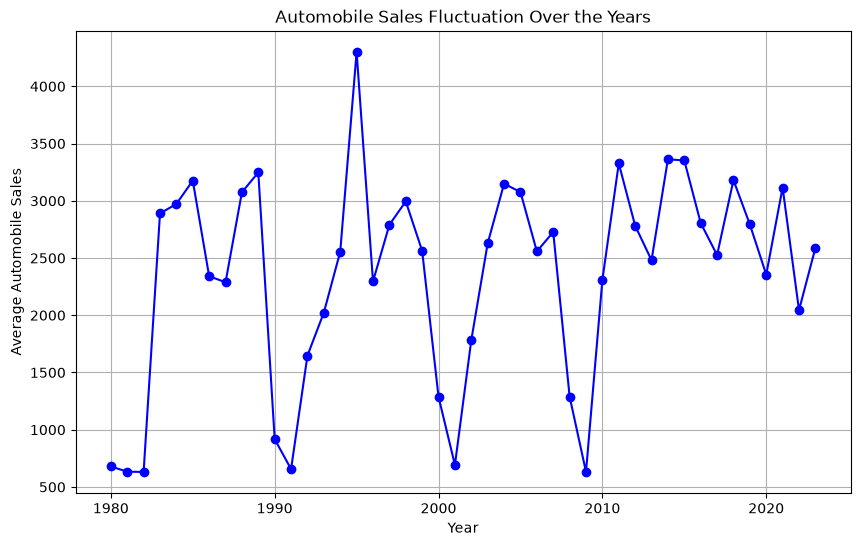

In [6]:
df_yearly = df.groupby('Year')['Automobile_Sales'].mean()

df_yearly.plot(kind='line', figsize=(10, 6), marker='o', color='blue')
plt.title('Automobile Sales Fluctuation Over the Years')
plt.xlabel('Year')
plt.ylabel('Average Automobile Sales')
plt.grid(True)
plt.show()

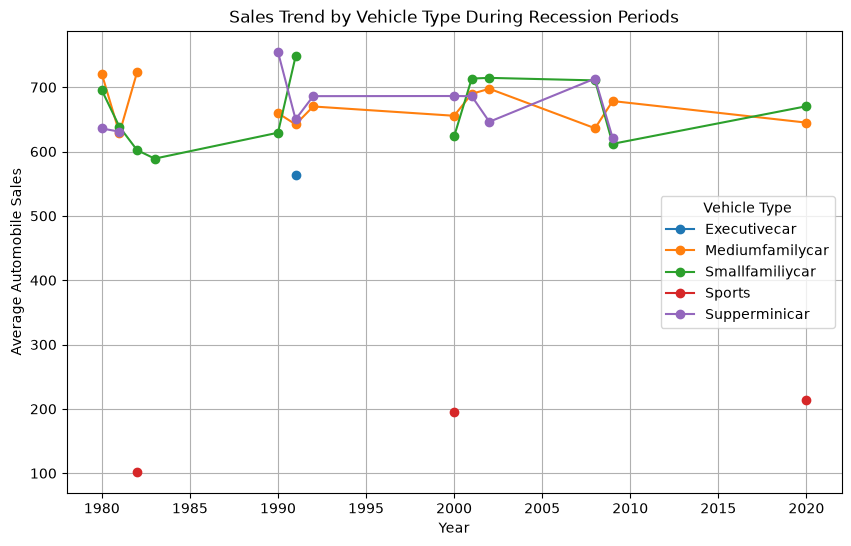

In [7]:
df_rec = df[df['Recession'] == 1]
df_grouped = df_rec.groupby(['Year', 'Vehicle_Type'])['Automobile_Sales'].mean().unstack()

df_grouped.plot(kind='line', figsize=(10, 6), marker='o')
plt.title('Sales Trend by Vehicle Type During Recession Periods')
plt.xlabel('Year')
plt.ylabel('Average Automobile Sales')
plt.legend(title='Vehicle Type')
plt.grid(True)
plt.show()

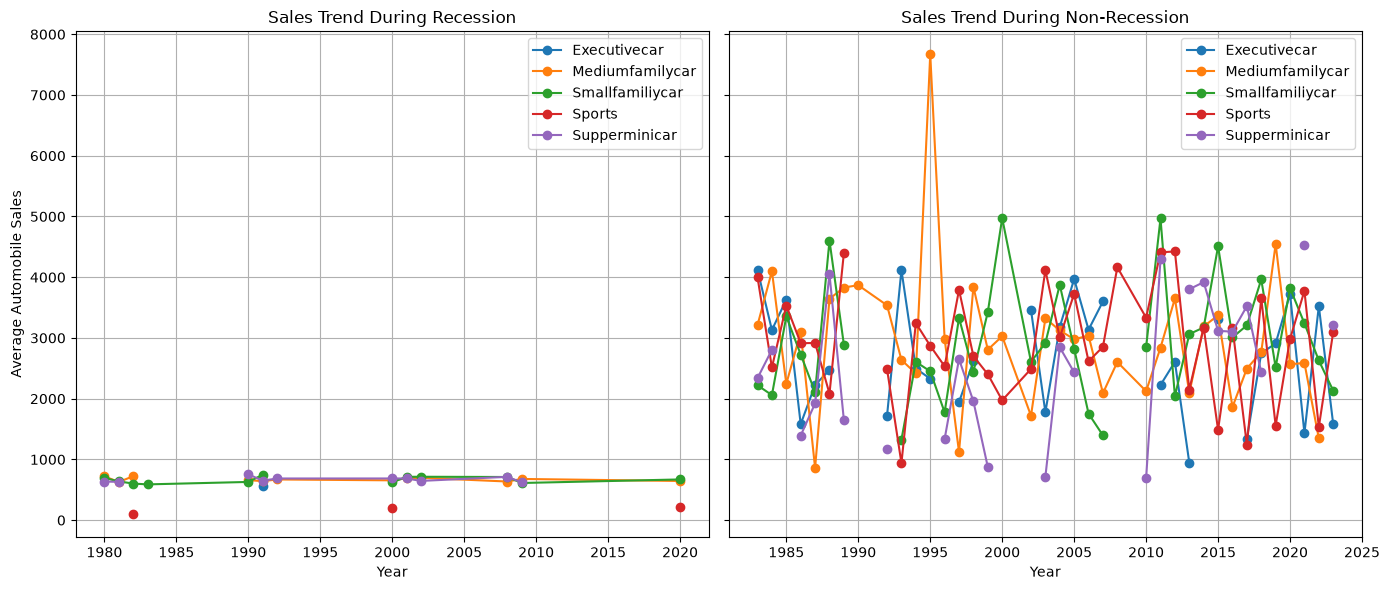

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

# Recession period
df_rec = df[df['Recession'] == 1].groupby(['Year', 'Vehicle_Type'])['Automobile_Sales'].mean().unstack()
for col in df_rec.columns:
    axes[0].plot(df_rec.index, df_rec[col], marker='o', label=col)
axes[0].set_title('Sales Trend During Recession')
axes[0].set_xlabel('Year')
axes[0].set_ylabel('Average Automobile Sales')
axes[0].legend()
axes[0].grid(True)

# Non-recession period
df_non_rec = df[df['Recession'] == 0].groupby(['Year', 'Vehicle_Type'])['Automobile_Sales'].mean().unstack()
for col in df_non_rec.columns:
    axes[1].plot(df_non_rec.index, df_non_rec[col], marker='o', label=col)
axes[1].set_title('Sales Trend During Non-Recession')
axes[1].set_xlabel('Year')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

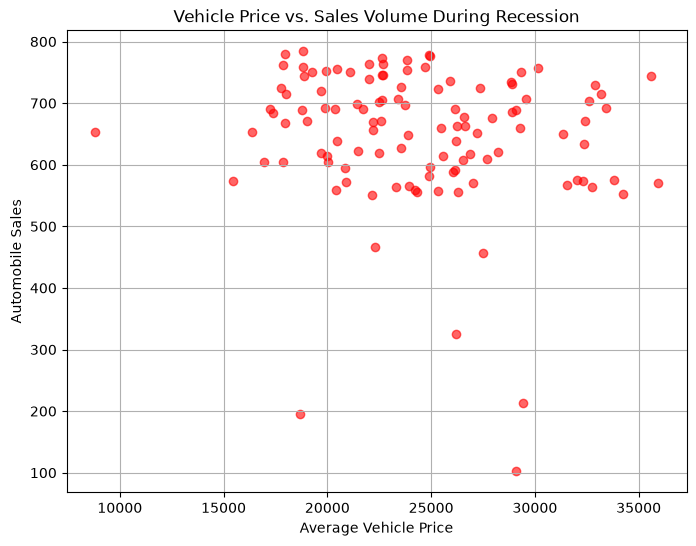

In [9]:
df_rec = df[df['Recession'] == 1]

plt.figure(figsize=(8, 6))
plt.scatter(df_rec['Price'], df_rec['Automobile_Sales'], color='red', alpha=0.6)
plt.title('Vehicle Price vs. Sales Volume During Recession')
plt.xlabel('Average Vehicle Price')
plt.ylabel('Automobile Sales')
plt.grid(True)
plt.show()

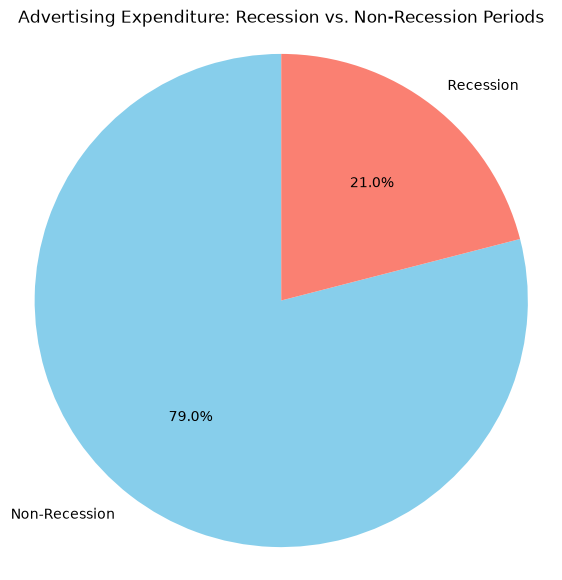

In [10]:
rec_adv = df.groupby('Recession')['Advertising_Expenditure'].sum()

labels = ['Non-Recession', 'Recession']
plt.figure(figsize=(7, 7))
plt.pie(rec_adv, labels=labels, autopct='%1.1f%%', colors=['skyblue', 'salmon'], startangle=90)
plt.title('Advertising Expenditure: Recession vs. Non-Recession Periods')
plt.axis('equal')
plt.show()

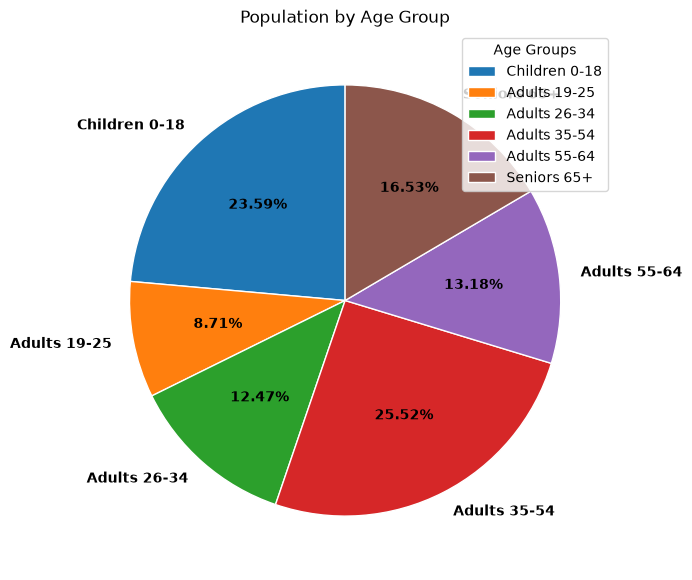

In [11]:
import matplotlib.pyplot as plt

# Data
age_groups = [
    "Children 0-18",
    "Adults 19-25",
    "Adults 26-34",
    "Adults 35-54",
    "Adults 55-64",
    "Seniors 65+"
]

population = [
    75307800,
    27799100,
    39817700,
    81478600,
    42061700,
    52784400
]

# a, b, c, d - Pie chart with percentage, colors, legend and bold labels
plt.figure(figsize=(9, 7))

plt.pie(
    population,
    labels=age_groups,
    autopct="%1.2f%%",
    startangle=90,
    wedgeprops={"edgecolor": "white"},
    textprops={"fontweight": "bold"}
)

plt.title("Population by Age Group")
plt.legend(age_groups, title="Age Groups", loc="best")
plt.show()

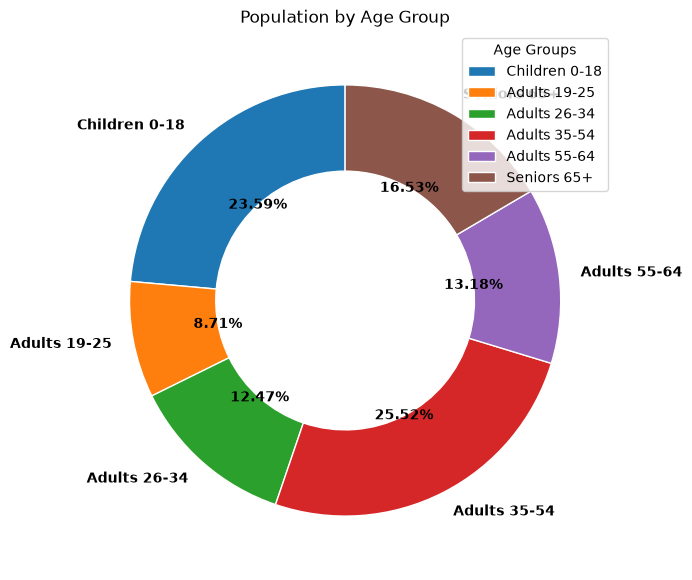

In [12]:
plt.figure(figsize=(9, 7))

plt.pie(
    population,
    labels=age_groups,
    autopct="%1.2f%%",
    startangle=90,
    wedgeprops={"width": 0.4, "edgecolor": "white"},
    textprops={"fontweight": "bold"}
)

plt.title("Population by Age Group")
plt.legend(age_groups, title="Age Groups", loc="best")
plt.show()